In [8]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import MinMaxScaler, OrdinalEncoder, OneHotEncoder

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import KFold, cross_val_score
import joblib

In [4]:
# importation du dataset

import pandas as pd

df = pd.read_csv('../data/flights.csv')


# df.head(10)
# print(df.ndim,df.shape)
df.info()
# df.describe()
df[['duration', 'days_left', 'price']].corr()


<class 'pandas.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  str    
 2   flight            300153 non-null  str    
 3   source_city       300153 non-null  str    
 4   departure_time    300153 non-null  str    
 5   stops             300153 non-null  str    
 6   arrival_time      300153 non-null  str    
 7   destination_city  300153 non-null  str    
 8   class             300153 non-null  str    
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), str(8)
memory usage: 42.9 MB


,duration,days_left,price
duration,1.000000,-0.039157,0.204222
days_left,-0.039157,1.000000,-0.091949
price,0.204222,-0.091949,1.000000


In [ ]:
# possible variables types 
    #  variables qualitatives nominales
    #  variables qualitatives ordinales
    #  variables quantatives discretes
    #  variables quantatives continues
# variables categorielles nominales
airline = ['SpiceJet','AirAsia','Vistara','GO_FIRST','Indigo','Air_India'] 
sourceCity=['delhi','Mumbai','Bangalore','Kolkata','Hyderabad','Chennai']
departureTime=['Morning','Early_Morning','Evening','Night','Afternoon','Late_Night']
stops=['zero','one','two_or_more']
arrivalTime=['Morning','Early_Morning','Evening','Night','Afternoon','Late_Night']
destinationCity=['Mumbai', 'Bangalore', 'Kolkata', 'Hyderabad', 'Chennai', 'Delhi']
# variables categorielles ordinales
classe=['Economy', 'Business']
# variables quantatives continues
VQC=['duration','price','days_left']
#  variables quantatives discretes
VQD=['flight']
# variable cible
VC=['price']
# countflight=df['price'].unique()
# print(countflight)

[ 5953  5956  5955 ... 87051 74731 77105]


In [1]:
import matplotlib.pyplot as plt
import pandas as pd 

         stops   count  frequency
0          one  250863  83.578375
1         zero   36004  11.995216
2  two_or_more   13286   4.426409


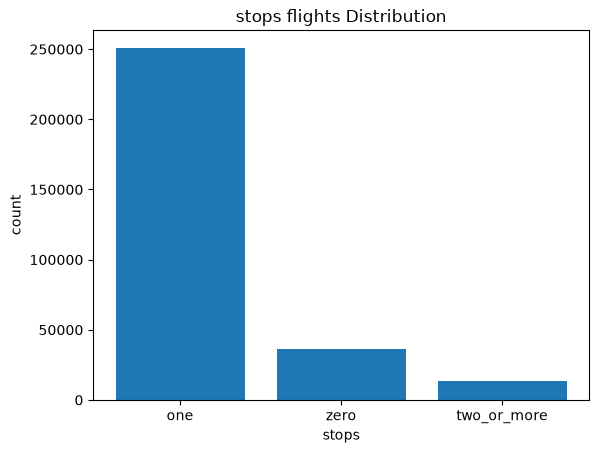

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd 
def statsGraphCategorielle(feature):
    featureStats=pd.DataFrame()
    featureStats = df[feature].value_counts().reset_index()
    featureStats['frequency']=round(((featureStats['count']/featureStats['count'].sum()) * 100),2)
    print(featureStats)
    plt.bar(featureStats[feature],featureStats['count'])
    plt.xlabel(feature)
    plt.ylabel('count')
    plt.title(f'{feature} flights Distribution')
    plt.show()

statsGraphCategorielle('stops')

        Unnamed: 0    airline   flight source_city departure_time  \
10534        10534    Vistara   UK-706       Delhi      Afternoon   
10535        10535    Vistara   UK-706       Delhi      Afternoon   
10540        10540  Air_India  AI-9887       Delhi  Early_Morning   
10891        10891    Vistara   UK-706       Delhi      Afternoon   
10892        10892    Vistara   UK-706       Delhi      Afternoon   
...            ...        ...      ...         ...            ...   
296064      296064  Air_India   AI-440     Chennai  Early_Morning   
296297      296297  Air_India   AI-440     Chennai  Early_Morning   
296391      296391  Air_India   AI-440     Chennai  Early_Morning   
296716      296716  Air_India   AI-440     Chennai  Early_Morning   
297661      297661  Air_India   AI-440     Chennai  Early_Morning   

              stops arrival_time destination_city     class  duration  \
10534   two_or_more        Night        Bangalore   Economy     31.25   
10535   two_or_more      

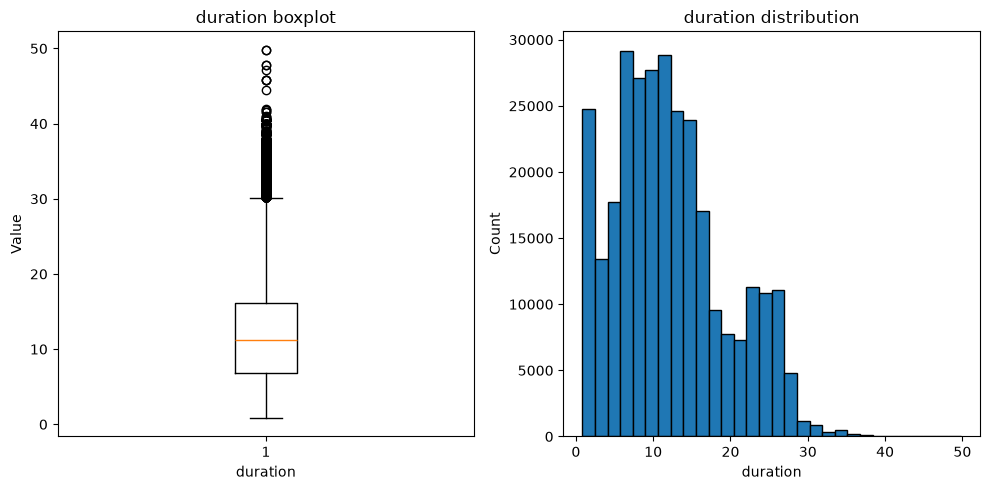

In [11]:
import matplotlib.pyplot as plt

def statsGraphquantitative(feature):
    quantile25 = df[feature].quantile(0.25)
    quantile75 = df[feature].quantile(0.75)
    
    IQR = quantile75 - quantile25
    
    LowerHalf = quantile25 - 1.5 * IQR
    UpperHalf = quantile75 + 1.5 * IQR
    
    outliers = df[
        (df[feature] > UpperHalf) |
        (df[feature] < LowerHalf)
    ]
    
    
    print(outliers)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

    # Boxplot
    ax1.boxplot(df[feature])
    ax1.set_xlabel(feature)
    ax1.set_ylabel('Value')
    ax1.set_title(f'{feature} boxplot')

    # Histogram
    ax2.hist(df[feature], bins=30, edgecolor='black')
    ax2.set_xlabel(feature)
    ax2.set_ylabel('Count')
    ax2.set_title(f'{feature} distribution')

    plt.tight_layout()
    plt.show()

statsGraphquantitative('duration')


          duration     price
duration  1.000000  0.204222
price     0.204222  1.000000


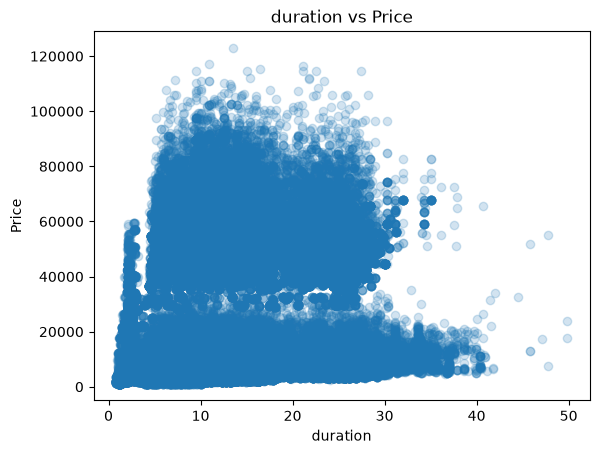

In [64]:
def analyseMutlivarieequantitative(feature):
    correlation = df[[feature, 'price']].corr()
    print(correlation)
    plt.scatter(df[feature], df['price'], alpha=0.2)
    plt.xlabel(feature)
    plt.ylabel('Price')
    plt.title(f'{feature} vs Price')
    plt.show()

analyseMutlivarieequantitative('duration')
# cross = pd.crosstab(df['destination_city'],df['arrival_time'])
# cross



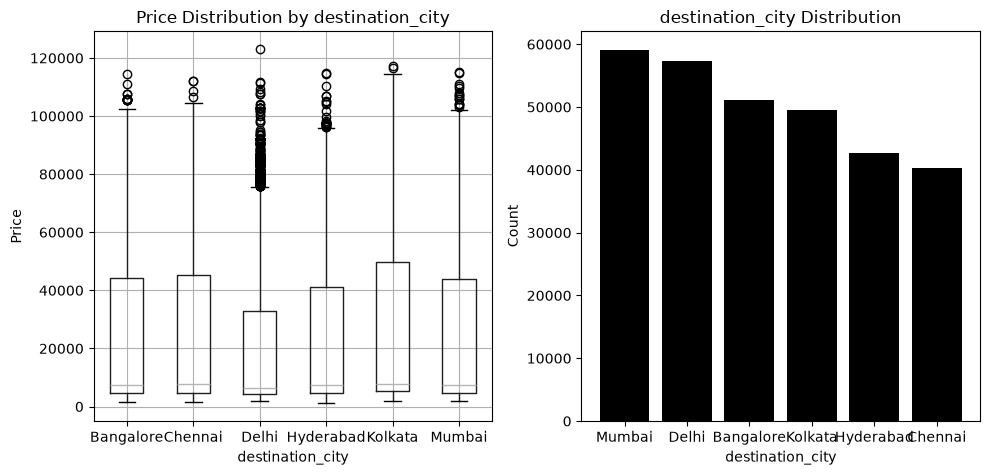

In [68]:
import matplotlib.pyplot as plt

def analyseMutlivarieequalitative(feature):

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

    df.boxplot(
        column='price',
        by=feature,
        ax=ax1
    )

    ax1.set_xlabel(feature)
    ax1.set_ylabel('Price')
    ax1.set_title(f'Price Distribution by {feature}')

    # Bar chart: frequency of each category
    counts = df[feature].value_counts()

    ax2.bar(
        counts.index,
        counts.values,
        color='black'
    )

    ax2.set_xlabel(feature)
    ax2.set_ylabel('Count')
    ax2.set_title(f'{feature} Distribution')

    plt.suptitle('')  # removes pandas default title
    plt.tight_layout()
    plt.show()


analyseMutlivarieequalitative('destination_city')

In [1]:
import sklearn
print(sklearn.__version__)

1.9.1


In [ ]:
def stopsMapping():
    mapping = {
        'zero': 0,
        'one': 1,
        'two_or_more': 2
    }

    df['stops_encoded'] = df['stops'].map(mapping)
    # df.drop('stops', axis=1, inplace=True)


def classMapping():
    mapping = {
        'Economy': 0,
        'Business': 1,
    }

    df['class_encoded'] = df['class'].map(mapping)
    # df.drop('stops', axis=1, inplace=True)


df

,Unnamed: 0,airline,flight,source_city,departure_time,arrival_time,destination_city,class,duration,days_left,price,stops_encoded,class_encoded
0,0,SpiceJet,SG-8709,Delhi,Evening,Night,Mumbai,Economy,2.17,1,5953,0,0
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,Morning,Mumbai,Economy,2.33,1,5953,0,0
2,2,AirAsia,I5-764,Delhi,Early_Morning,Early_Morning,Mumbai,Economy,2.17,1,5956,0,0
3,3,Vistara,UK-995,Delhi,Morning,Afternoon,Mumbai,Economy,2.25,1,5955,0,0
4,4,Vistara,UK-963,Delhi,Morning,Morning,Mumbai,Economy,2.33,1,5955,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
300148,300148,Vistara,UK-822,Chennai,Morning,Evening,Hyderabad,Business,10.08,49,69265,1,1
300149,300149,Vistara,UK-826,Chennai,Afternoon,Night,Hyderabad,Business,10.42,49,77105,1,1
300150,300150,Vistara,UK-832,Chennai,Early_Morning,Night,Hyderabad,Business,13.83,49,79099,1,1
300151,300151,Vistara,UK-828,Chennai,Early_Morning,Evening,Hyderabad,Business,10.00,49,81585,1,1


In [32]:
def categriellENconding():
    categorical_columns = [
        'airline',
        'source_city',
        'departure_time',
        'arrival_time',
        'destination_city'
    ]
    global df
    df = pd.get_dummies(
        df,
        columns=categorical_columns
    )
    # df = df.drop(columns=['Unnamed: 0'])

categriellENconding()
stopsMapping()
classMapping()
print(df.info())

# usedFeature = df.columns.tolist()

<class 'pandas.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 39 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Unnamed: 0                    300153 non-null  int64  
 1   flight                        300153 non-null  str    
 2   stops                         300153 non-null  str    
 3   class                         300153 non-null  str    
 4   duration                      300153 non-null  float64
 5   days_left                     300153 non-null  int64  
 6   price                         300153 non-null  int64  
 7   airline_AirAsia               300153 non-null  bool   
 8   airline_Air_India             300153 non-null  bool   
 9   airline_GO_FIRST              300153 non-null  bool   
 10  airline_Indigo                300153 non-null  bool   
 11  airline_SpiceJet              300153 non-null  bool   
 12  airline_Vistara               300153 non-null  bool   


In [12]:
usedFeature = df.columns
usedFeature=usedFeature.drop(['flight','stops','class'])
# usedFeature.to_frame()
explicativeFeature=df[['airline', 'flight', 'source_city', 'departure_time',
       'stops', 'arrival_time', 'destination_city', 'class', 'duration',
       'days_left', 'price']]

cibleFeature=df['price']

explicativeFeature
cibleFeature

0          5953
1          5953
2          5956
3          5955
4          5955
          ...  
300148    69265
300149    77105
300150    79099
300151    81585
300152    81585
Name: price, Length: 300153, dtype: int64

In [13]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    explicativeFeature,
    cibleFeature,
    test_size=0.2,
    random_state=42
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)



X_train: (240122, 11)
X_test: (60031, 11)
y_train: (240122,)
y_test: (60031,)


In [ ]:
# numerical_features = [
#     'duration',
#     'days_left'
# ]

# scaler = MinMaxScaler()

# X_scaled = scaler.fit_transform(df[numerical_features])

# encoder = OneHotEncoder(sparse_output=False)

# X_encoded = encoder.fit_transform(df[categorical_features])

# scaled_df = pd.DataFrame(
#     X_scaled,
#     columns=scaler.get_feature_names_out(numerical_features)
# )

# encoded_df = pd.DataFrame(
#     X_encoded,
#     columns=encoder.get_feature_names_out(categorical_features)
# )


# final_df = pd.concat(
#     [scaled_df, encoded_df],
#     axis=1
# )

In [9]:
from sklearn.preprocessing import MinMaxScaler,OrdinalEncoder,OneHotEncoder
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor

categorical_features = [
    'airline',
    'source_city',
    'departure_time',
    'arrival_time',
    'destination_city',
]

numerical_features = [
    'duration',
    'days_left'
]

ordinal_features = [
    'class', 
    'stops'
]

ordinal_encoder = OrdinalEncoder(
    categories=[
        ['Economy', 'Business'],       
        ['zero', 'one', 'two_or_more'] 
    ]
)
preprocessor = ColumnTransformer([
    ('ordinal',
     ordinal_encoder,
     ordinal_features),

    ('categorielle', OneHotEncoder(
        sparse_output=False,
        drop='first',
        handle_unknown='ignore'
    ), categorical_features),

    ('numerical', MinMaxScaler(), numerical_features)
])


model_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', RandomForestRegressor(n_estimators=50,
        max_depth=15,random_state=42))
])

# X = df.drop('price', axis=1)
# y = df['price']

# model_pipeline.fit(X, y)

# y_pred = model_pipeline.predict(X)
# comparaison = pd.DataFrame({
#     'prix reel': y.values,
#     'prix predit': y_pred
# })

# comparaison


In [14]:
X = df.drop('price', axis=1)
y = df['price']

model_pipeline.fit(X_train, y_train)


with open('../artifacts/flight_price_model.joblib', 'wb') as f:
    joblib.dump(model_pipeline, f)

In [5]:
categorical_features = [
    'airline',
    'source_city',
    'departure_time',
    'arrival_time',
    'destination_city',
]

numerical_features = [
    'duration',
    'days_left'
]

ordinal_features = [
    'class', 
    'stops'
]

ordinal_encoder = OrdinalEncoder(
    categories=[
        ['Economy', 'Business'],       
        ['zero', 'one', 'two_or_more'] 
    ]
)
preprocessor = ColumnTransformer([
    ('ordinal',
     ordinal_encoder,
     ordinal_features),

    ('categorielle', OneHotEncoder(
        sparse_output=False,
        drop='first',
        handle_unknown='ignore'
    ), categorical_features),

    ('numerical', MinMaxScaler(), numerical_features)
])




In [6]:
model_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', RandomForestRegressor(n_estimators=100,random_state=42))
])

In [105]:
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    model_pipeline,
    X_train,
    y_train,
    cv=kf,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

mae_scores = -cv_scores

print("MAE for each fold:", mae_scores)
print("Mean MAE:", mae_scores.mean())
print("Std MAE:", mae_scores.std())

MAE for each fold: [1117.62249479 1108.30528978 1117.29314191 1113.57316773 1119.93990386]
Mean MAE: 1115.3467996145328
Std MAE: 4.0692081359675925


In [ ]:
import joblib
import json

In [ ]:
y_test = y_test.squeeze()


errors = np.abs(y_pred - y_test)

mae = np.mean(errors)

std = np.std(errors)

se = std / np.sqrt(len(errors))

ci = [(mae - 1.96*se), (mae + 1.96*se)]

# errors
d=pd.DataFrame({
    'test':y_test,
    'pred':y_pred,
    'marge':errors,
})
mae


np.float64(1077.601211532375)

In [17]:
import joblib
import json
model_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', RandomForestRegressor(n_estimators=100,random_state=42))
])

model_pipeline.fit(X_train, y_train.flatten())

with open('../artifacts/flight_price_model.joblib', 'wb') as f:
    joblib.dump(model_pipeline, f)


c:\Users\youcode\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


In [7]:
X = df.drop('price', axis=1)
y = df['price']

model_pipeline.fit(X_train, y_train)


with open('../artifacts/flight_price_model.joblib', 'wb') as f:
    joblib.dump(model_pipeline, f)

NameError: name 'X_train' is not defined